# Practical No-05: Image Generation using Pretrained Stable Diffusion

**Student Information:**
* **Name of Student:** Gandhar Sunil Chafle
* **PRN Number:** 202401110018
* **Batch:** A2
* **Date of Submission:** 27 October 2026
* **Class:** T.Y. B.Tech
* **Department:** CSE AIML
* **Institute:** MIT Academy of Engineering (MIT AOE)
* **Course:** Generative AI Lab


In [1]:
%pip install -q -U diffusers transformers accelerate safetensors matplotlib

In [3]:
import time
import torch
import matplotlib.pyplot as plt

from diffusers import (
    StableDiffusionPipeline,
    PNDMScheduler,
    DDIMScheduler,
    EulerDiscreteScheduler,
    EulerAncestralDiscreteScheduler,
    DPMSolverMultistepScheduler
)

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)

All libraries imported successfully!
PyTorch version: 2.11.0+cu130


In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

if device == "cpu":
    dtype = torch.float32
else:
    dtype = torch.float16

pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=dtype,
    use_safetensors=True
)

pipe = pipe.to(device)

# Save scheduler configuration for the experiments
scheduler_config = pipe.scheduler.config

print("Model loaded successfully.")
print("Scheduler:", type(pipe.scheduler).__name__)

Using device: cuda


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Model loaded successfully.
Scheduler: PNDMScheduler


In [5]:
def generate(prompt, steps=30, guidance=7.5, seed=42):

    generator = torch.Generator(
        device=device
    ).manual_seed(seed)

    # Synchronize GPU before timing
    if device == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.inference_mode():
        result = pipe(
            prompt,
            num_inference_steps=steps,
            guidance_scale=guidance,
            generator=generator
        )

    if device == "cuda":
        torch.cuda.synchronize()

    seconds = time.perf_counter() - start

    return result.images[0], seconds

In [8]:
import matplotlib.pyplot as plt
import math

def show_images(images, titles, columns=3):
    if not images:
        print("No images available to display.")
        return

    rows = math.ceil(len(images) / columns)

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(5 * columns, 5 * rows),
        squeeze=False
    )

    for i, (image, title) in enumerate(zip(images, titles)):
        ax = axes.flat[i]
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")

    # Hide unused subplot positions
    for i in range(len(images), rows * columns):
        axes.flat[i].axis("off")

    plt.tight_layout()
    plt.show()

print("show_images() function defined successfully!")

show_images() function defined successfully!


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

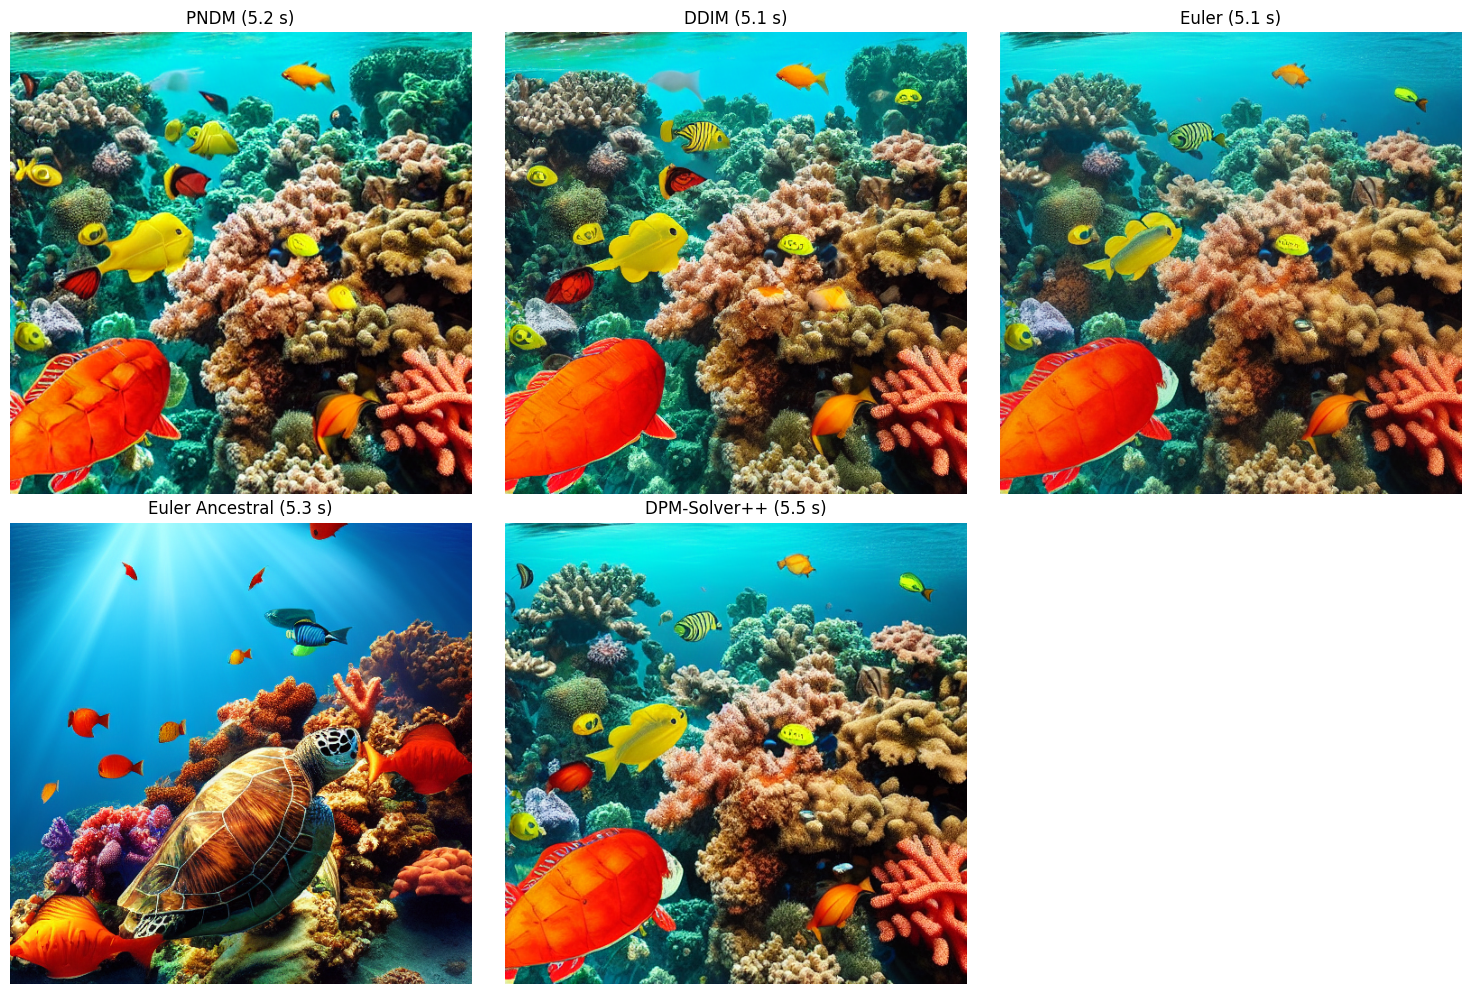

,Scheduler,Inference Steps,Guidance Scale,Seed,Generation Time (seconds)
0,PNDM,30,7.5,42,5.24
1,DDIM,30,7.5,42,5.10
2,Euler,30,7.5,42,5.12
3,Euler Ancestral,30,7.5,42,5.29
4,DPM-Solver++,30,7.5,42,5.46


In [9]:
prompt = (
     "A beautiful underwater coral reef filled with colorful fish, "
    "sunbeams penetrating clear blue water, sea turtles, "
    "vibrant marine life, realistic underwater photography"
)

schedulers = {
    "PNDM": PNDMScheduler,
    "DDIM": DDIMScheduler,
    "Euler": EulerDiscreteScheduler,
    "Euler Ancestral": EulerAncestralDiscreteScheduler,
    "DPM-Solver++": DPMSolverMultistepScheduler,
}

images = []
titles = []
scheduler_results = []

for name, scheduler_class in schedulers.items():

    pipe.scheduler = scheduler_class.from_config(
        scheduler_config
    )

    img, sec = generate(
        prompt,
        steps=30,
        guidance=7.5,
        seed=42
    )

    images.append(img)
    titles.append(f"{name} ({sec:.1f} s)")

    scheduler_results.append({
        "Scheduler": name,
        "Inference Steps": 30,
        "Guidance Scale": 7.5,
        "Seed": 42,
        "Generation Time (seconds)": round(sec, 2)
    })

show_images(images, titles)

import pandas as pd

scheduler_df = pd.DataFrame(scheduler_results)
display(scheduler_df)